# Astana Apartment Price Prediction — Endterm Project

**Course:** Machine Learning Algorithms  
**Group:** SE-2431  
**Team:** Nurkhan Kuanyshov and Bakytzhan Jangazy

## 1. Problem statement and research objective

Astana apartment asking prices vary with size, layout, location, floor, building characteristics and advertised amenities. A transparent estimate can help buyers and sellers compare listings, but it is not an official valuation. Our research question is: **Can we predict the asking price of an apartment in Astana using its area, location, rooms, floor, building characteristics and amenities?**

This is a regression task. The original target remains `price`; models learn `log1p(price)` because prices are right-skewed. Success is assessed using log-scale RMSE, MAE and R², plus KZT MAE and median absolute percentage error (MedAPE) on the original price scale. The test partition is reserved for one final evaluation only.

This endterm notebook extends—not replaces—the preserved midterm notebook. All metrics and charts below are computed from the supplied Kaggle CSV; no historical midterm metric is copied into the results.


In [1]:
import importlib.util
import platform
import re
import warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score)
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA_FILENAME = "astana_real_estate_dataset.csv"
DATASET_HANDLE = "turarr/astana-real-estate-dataset"
TARGET = "price"
RANDOM_STATE = 42
CURRENT_YEAR = 2026
FIG_DIR = ROOT / "visualizations"
for folder in ["eda", "clustering", "pca", "ann", "evaluation"]:
    (FIG_DIR / folder).mkdir(parents=True, exist_ok=True)
(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "reports").mkdir(exist_ok=True)

print(f"Python: {platform.python_version()} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")
print(f"NumPy: {np.__version__} | Matplotlib: {matplotlib.__version__} | seaborn: {sns.__version__} | joblib: {joblib.__version__}")
local_data = ROOT / DATA_FILENAME
kaggle_input = Path("/kaggle/input")
attached_files = list(kaggle_input.rglob(DATA_FILENAME)) if kaggle_input.exists() else []
if local_data.exists():
    DATA_PATH = local_data
    DATA_SOURCE = "local project copy"
elif attached_files:
    DATA_PATH = attached_files[0]
    DATA_SOURCE = "Kaggle notebook input"
else:
    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError(
            "Dataset is not attached or stored locally. Install project dependencies "
            "(including kagglehub), then rerun this cell with internet access."
        ) from exc
    downloaded_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
    downloaded_files = list(downloaded_dir.rglob("*.csv"))
    exact_matches = [path for path in downloaded_files if path.name.lower() == DATA_FILENAME.lower()]
    if exact_matches:
        DATA_PATH = exact_matches[0]
    elif len(downloaded_files) == 1:
        DATA_PATH = downloaded_files[0]
    else:
        raise FileNotFoundError(
            f"Kaggle dataset {DATASET_HANDLE} downloaded, but the expected CSV was not uniquely identified. "
            f"CSV files found: {[str(path) for path in downloaded_files]}"
        )
    DATA_SOURCE = f"KaggleHub ({DATASET_HANDLE})"
print(f"Dataset source: {DATA_SOURCE} | file: {DATA_PATH}")


Python: 3.14.10 | pandas: 3.1.1 | scikit-learn: 1.9.1
NumPy: 2.5.4 | Matplotlib: 3.11.2 | seaborn: 0.13.2 | joblib: 1.6.0
Dataset source: local project copy | file: /Users/nurkhan/Downloads/endterm_mla/endterm_machinelearningalgirithms/astana_real_estate_dataset.csv


## 2. Dataset description

The source is the **Astana Real Estate Dataset** by `turarr` on [Kaggle](https://www.kaggle.com/datasets/turarr/astana-real-estate-dataset). It consists of advertised properties scraped from Krisha.kz. The notebook first looks for an attached Kaggle input or an optional local CSV; if neither exists, it downloads the public dataset through KaggleHub. The next cell reports the original row and column counts and actual feature names from the file.

Important limitations: these are advertised asking prices, not verified transaction prices; listings may be duplicated; seller-entered fields can be incomplete or inaccurate; and the data represent a particular collection period rather than the full housing market.


In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Original dataset: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "missing_%": (df_raw.isna().mean() * 100).round(1), "unique": df_raw.nunique()}).sort_values("missing_%", ascending=False))


Original dataset: 5,003 rows × 23 columns


,url,title,price,security,ceiling_height,Год постройки,district,residential_complex,furnished,parking,bathroom_type,apartment_condition,building_type,rooms,current_floor,total_floors,area_m2,address,district_lat,district_lon,apartment_lat,apartment_lon,coord_level
0,https://krisha.kz/a/show/683656844,"3-комнатная квартира · 120 м², Сыганак — Кабан...",55000000,"домофон, видеонаблюдение",2.902672,2006,"Есильский район, Астана, Казахстан",7 Бочек,полностью,Во дворе/не указано,2 с/у и более,свежий ремонт,монолитный,3.0,6.0,11.0,120.00,Сыганак — Кабанбай батыра,51.120,71.430,51.122041,71.413101,Address
1,https://krisha.kz/a/show/1010380882,"2-комнатная квартира · 64.5 м² · 9/9 этаж, Тол...",45500000,"домофон, видеонаблюдение",3.000000,2022,"Нуринский район, Астана, Казахстан",Dastur,полностью,Во дворе/не указано,совмещенный,Не указано,кирпичный,2.0,9.0,9.0,64.50,Толе би 25,51.100,71.380,51.099779,71.389694,Complex
2,https://krisha.kz/a/show/1010251370,"2-комнатная квартира · 64.37 м² · 10/12 этаж, ...",32800000,"домофон, кодовый замок, видеодомофон",3.000000,2026,"Сарыаркинский район, Астана, Казахстан",Shalqar,без мебели,паркинг,совмещенный,черновая отделка,кирпичный,2.0,10.0,12.0,64.37,Чингиз Айтматов 77/11 — Мечеть Ырыскелді Кажы,51.170,71.410,51.170000,71.410000,District
3,https://krisha.kz/a/show/1010195327,"3-комнатная квартира · 115 м², Ивана Панфилова 85",75000000,"домофон, видеонаблюдение",3.200000,2026,"Сарыаркинский район, Астана, Казахстан",TANSU,без мебели,паркинг,совмещенный,Не указано,кирпичный,3.0,6.0,11.0,115.00,Ивана Панфилова 85,51.117,71.565,51.105860,71.500377,Complex
4,https://krisha.kz/a/show/1009176178,"2-комнатная квартира · 52 м² · 8/12 этаж, Кубр...",25000000,"домофон, видеонаблюдение",2.700000,2009,"Сарыаркинский район, Астана, Казахстан",Сайран,полностью,Во дворе/не указано,совмещенный,свежий ремонт,кирпичный,2.0,8.0,12.0,52.00,Кубрина 20/1,51.170,71.410,51.197097,71.475239,Complex


,dtype,missing_%,unique
url,str,0.0,4174
building_type,str,0.0,4
apartment_lon,float64,0.0,936
apartment_lat,float64,0.0,937
district_lon,float64,0.0,7
district_lat,float64,0.0,7
address,str,0.0,2920
area_m2,float64,0.0,1226
total_floors,float64,0.0,39
current_floor,float64,0.0,29


## 3. Cleaning and feature engineering

Cleaning converts formatted numeric text, extracts floor pairs where present, removes identifiers/free text and price-like leakage fields, removes exact duplicates, applies defensible range checks, and trims only the outer 1% of the target distribution. Imputation is deliberately deferred to model pipelines so it is learned only from training folds.

The engineered features are `house_age`, `is_first_floor`, `is_last_floor`, `floor_ratio`, and `area_per_room`. A distance-to-centre feature is added only if real latitude and longitude columns exist. It uses a fixed approximate Astana city-centre coordinate and does not use the target.


In [3]:
def to_number(series):
    cleaned = series.astype(str).str.replace(r"[^\d.,-]", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(cleaned, errors="coerce")

def first_matching(columns, pattern, numeric_only=False):
    for name in columns:
        if re.search(pattern, str(name), flags=re.I):
            return name
    return None

df = df_raw.copy()
if TARGET not in df:
    raise KeyError(f"Expected target column '{TARGET}' was not found. Available columns: {list(df.columns)}")
if not pd.api.types.is_numeric_dtype(df[TARGET]):
    df[TARGET] = to_number(df[TARGET])
df = df.dropna(subset=[TARGET]).query(f"{TARGET} > 0").copy()

# Extract fields formatted like '5 из 9' or '5/9' only when most non-null values match.
for col in list(df.select_dtypes(exclude="number").columns):
    parts = df[col].astype(str).str.extract(r"^\s*(\d+)\s*(?:из|/|of)\s*(\d+)\s*$", flags=re.I)
    if len(parts) and parts[0].notna().mean() > 0.5:
        df["current_floor"] = pd.to_numeric(parts[0])
        df["total_floors"] = pd.to_numeric(parts[1])
        df = df.drop(columns=col)

for col in list(df.select_dtypes(exclude="number").columns):
    if col == TARGET:
        continue
    parsed = to_number(df[col])
    non_null = df[col].notna().sum()
    if non_null and parsed.notna().sum() >= 0.9 * non_null:
        df[col] = parsed

drop_cols = []
for col in df.columns:
    low = str(col).lower()
    if col == TARGET:
        continue
    if re.search(r"url|link|title|descr|phone|(^|_)id$", low) or ("price" in low or "цена" in low):
        drop_cols.append(col)
    elif df[col].isna().mean() > 0.60:
        drop_cols.append(col)
    elif not pd.api.types.is_numeric_dtype(df[col]) and df[col].nunique(dropna=True) > 0.50 * len(df):
        drop_cols.append(col)
df = df.drop(columns=drop_cols).drop_duplicates().copy()

AREA_COL = "area_m2" if "area_m2" in df else first_matching(df.select_dtypes(include="number").columns, r"area|sq")
ROOMS_COL = "rooms" if "rooms" in df else first_matching(df.select_dtypes(include="number").columns, r"room")
YEAR_COL = first_matching(df.select_dtypes(include="number").columns, r"build.*year|year.*build|construction.*year|год.*постро|постро.*год")
FLOOR_COL = "current_floor" if "current_floor" in df else first_matching(df.select_dtypes(include="number").columns, r"(^|_)floor$")
TOTAL_FLOORS_COL = "total_floors" if "total_floors" in df else first_matching(df.select_dtypes(include="number").columns, r"total.*floor|floor.*total")
DISTRICT_COL = "district" if "district" in df else first_matching(df.columns, r"district")
LAT_COL = first_matching(df.select_dtypes(include="number").columns, r"(^|_)(lat|latitude)($|_)")
LON_COL = first_matching(df.select_dtypes(include="number").columns, r"(^|_)(lon|lng|longitude)($|_)")
print({"area": AREA_COL, "rooms": ROOMS_COL, "year": YEAR_COL, "floor": FLOOR_COL, "total_floors": TOTAL_FLOORS_COL, "district": DISTRICT_COL, "latitude": LAT_COL, "longitude": LON_COL})

before = len(df)
if AREA_COL: df = df[df[AREA_COL].between(10, 500)]
if ROOMS_COL: df = df[df[ROOMS_COL].between(1, 10)]
if YEAR_COL: df.loc[~df[YEAR_COL].between(1900, CURRENT_YEAR), YEAR_COL] = np.nan
if FLOOR_COL and TOTAL_FLOORS_COL:
    df = df[df[FLOOR_COL].between(1, 60) & df[TOTAL_FLOORS_COL].between(1, 80) & (df[FLOOR_COL] <= df[TOTAL_FLOORS_COL])]
lo, hi = df[TARGET].quantile([0.01, 0.99])
df = df[df[TARGET].between(lo, hi)].copy()

if YEAR_COL:
    df["house_age"] = CURRENT_YEAR - df[YEAR_COL]
    df = df.drop(columns=YEAR_COL)
if FLOOR_COL and TOTAL_FLOORS_COL:
    df["is_first_floor"] = (df[FLOOR_COL] == 1).astype(int)
    df["is_last_floor"] = (df[FLOOR_COL] == df[TOTAL_FLOORS_COL]).astype(int)
    df["floor_ratio"] = df[FLOOR_COL] / df[TOTAL_FLOORS_COL].replace(0, np.nan)
if AREA_COL and ROOMS_COL:
    df["area_per_room"] = df[AREA_COL] / df[ROOMS_COL].replace(0, np.nan)
if LAT_COL and LON_COL:
    # Haversine distance in km to a fixed approximate city-centre reference.
    lat1, lon1 = np.radians(df[LAT_COL]), np.radians(df[LON_COL])
    lat0, lon0 = np.radians(51.1694), np.radians(71.4491)
    a = np.sin((lat1-lat0)/2)**2 + np.cos(lat0)*np.cos(lat1)*np.sin((lon1-lon0)/2)**2
    df["distance_to_centre_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

print(f"Rows after cleaning: {len(df):,} (removed {before-len(df):,} after initial target/duplicate processing)")
print(f"Price range retained: {lo:,.0f}–{hi:,.0f} KZT")


{'area': 'area_m2', 'rooms': 'rooms', 'year': 'Год постройки', 'floor': 'current_floor', 'total_floors': 'total_floors', 'district': 'district', 'latitude': 'district_lat', 'longitude': 'district_lon'}
Rows after cleaning: 4,086 (removed 83 after initial target/duplicate processing)
Price range retained: 13,466,000–185,000,000 KZT


## 4. Exploratory data analysis

The printed skewness values quantify the long upper price tail and how much `log1p` reduces it. The area–price scatterplot shows whether asking prices tend to rise with floor area and how wide the price spread is at comparable sizes. District medians help compare typical advertised prices without letting a few luxury listings determine the comparison. Correlations describe pairwise numeric associations, not causal effects. The missingness summary identifies which fields require imputation.


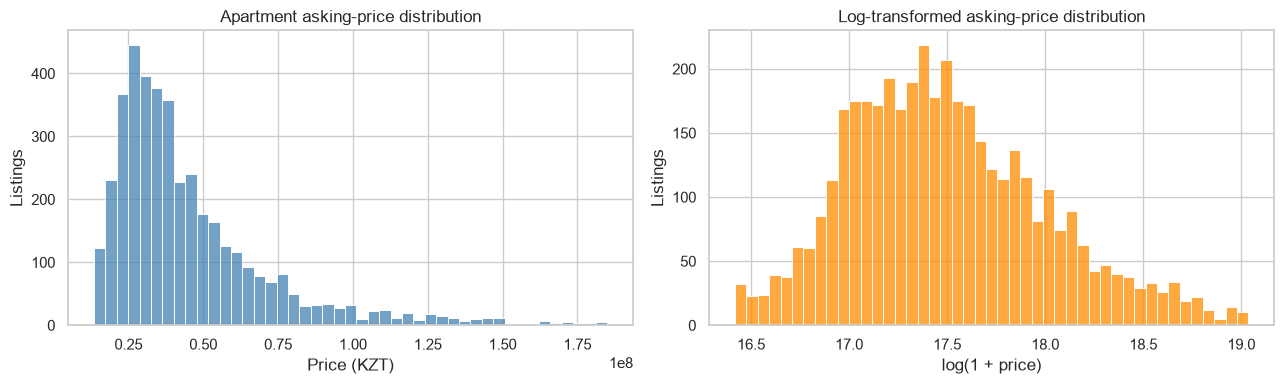

Raw price skewness: 1.95; log-price skewness: 0.50
Interpretation: a smaller absolute log-price skewness indicates that log1p has compressed the long upper tail; it does not make the price distribution normal by itself.


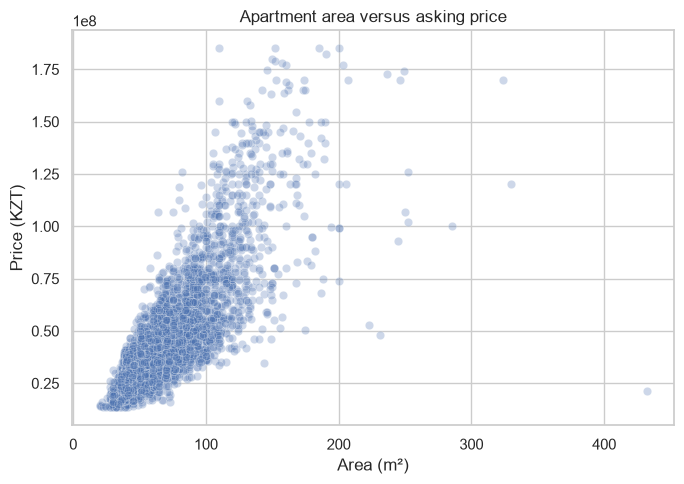

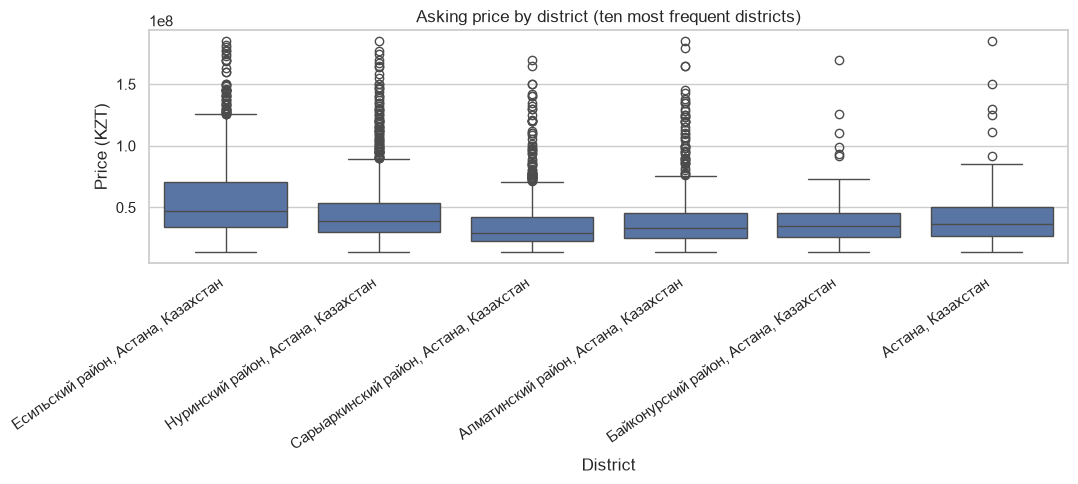

District interpretation: compare these medians only for districts with at least 20 retained listings; sample counts are shown to flag less reliable comparisons.


,median,count
district,,
"Есильский район, Астана, Казахстан",47150000.0,1096
"Нуринский район, Астана, Казахстан",38818780.0,1203
"Астана, Казахстан",36250000.0,140
"Байконурский район, Астана, Казахстан",35000000.0,177
"Алматинский район, Астана, Казахстан",33000000.0,644
"Сарыаркинский район, Астана, Казахстан",29500000.0,826


Area-price Pearson correlation: 0.797. This is a linear association and does not account for district, quality, or other listing differences.


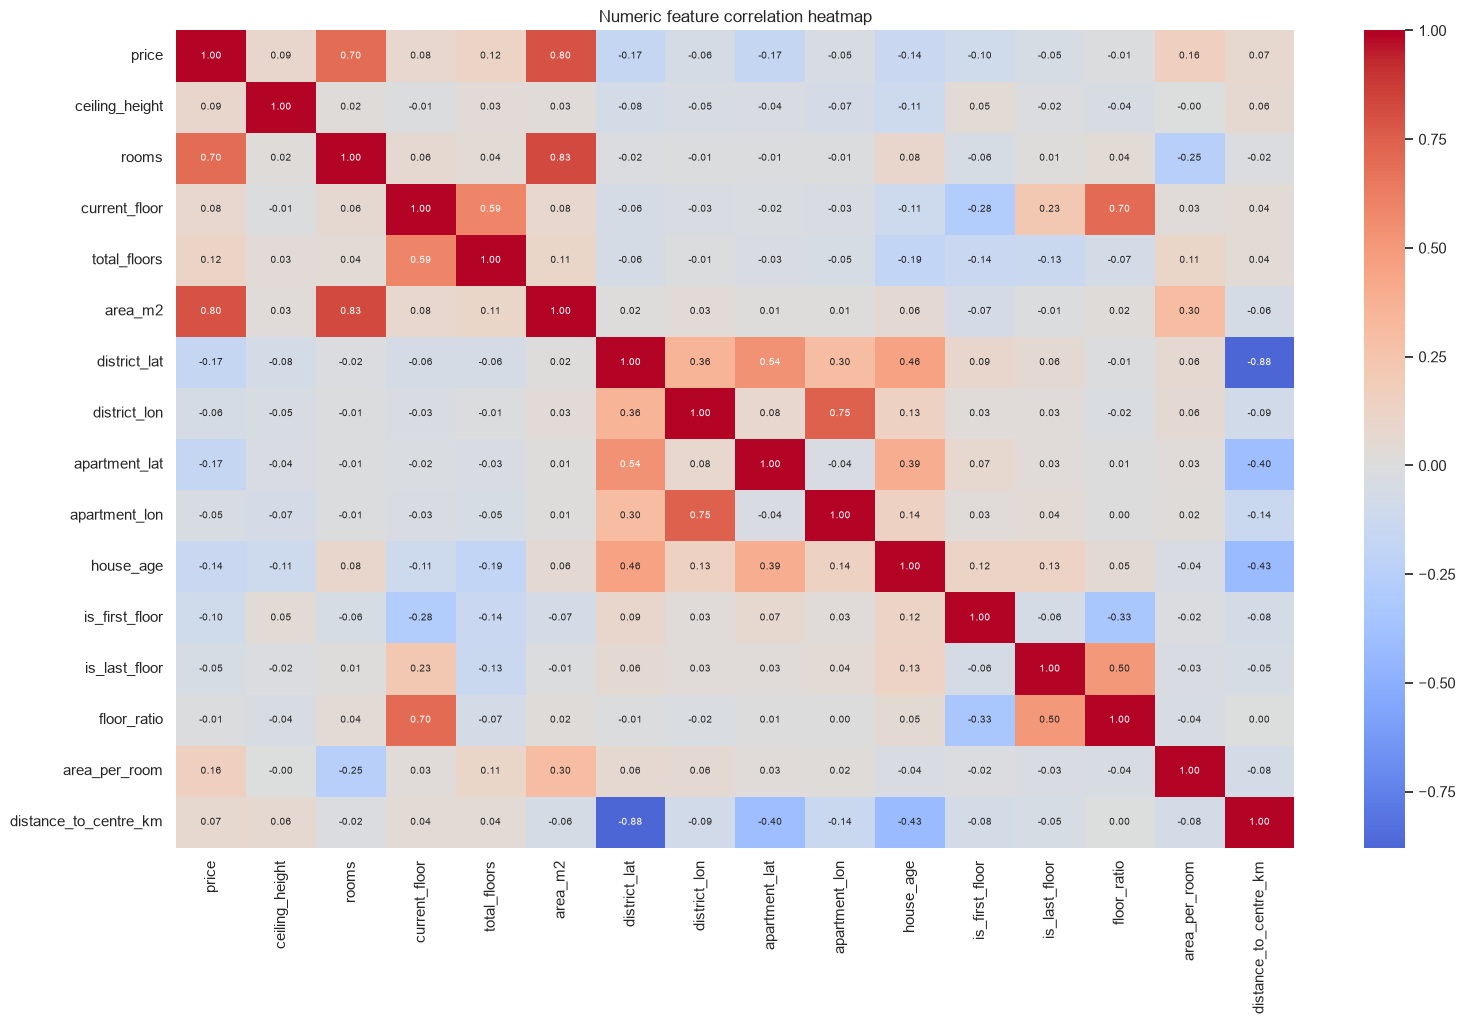

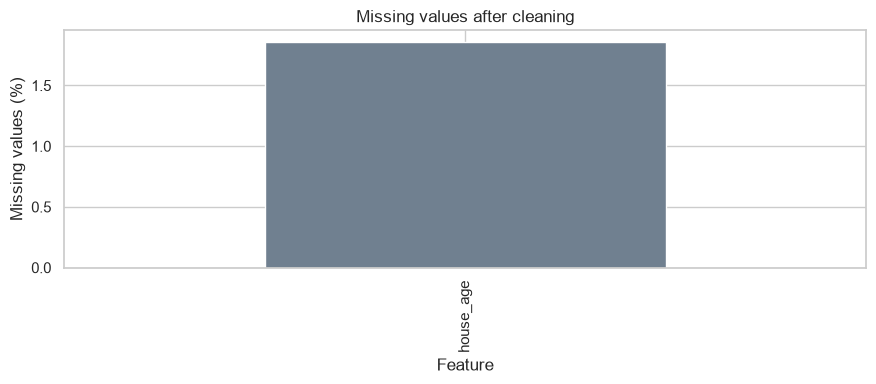

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], bins=45, ax=axes[0], color="steelblue")
axes[0].set(title="Apartment asking-price distribution", xlabel="Price (KZT)", ylabel="Listings")
sns.histplot(np.log1p(df[TARGET]), bins=45, ax=axes[1], color="darkorange")
axes[1].set(title="Log-transformed asking-price distribution", xlabel="log(1 + price)", ylabel="Listings")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda" / "price_distributions.png", dpi=160); plt.show()
print(f"Raw price skewness: {df[TARGET].skew():.2f}; log-price skewness: {np.log1p(df[TARGET]).skew():.2f}")
print("Interpretation: a smaller absolute log-price skewness indicates that log1p has compressed the long upper tail; it does not make the price distribution normal by itself.")

if AREA_COL:
    plt.figure(figsize=(7, 5)); sns.scatterplot(data=df, x=AREA_COL, y=TARGET, alpha=.28)
    plt.title("Apartment area versus asking price"); plt.xlabel("Area (m²)"); plt.ylabel("Price (KZT)")
    plt.tight_layout(); plt.savefig(FIG_DIR / "eda" / "area_vs_price.png", dpi=160); plt.show()
if DISTRICT_COL and DISTRICT_COL in df:
    top = df[DISTRICT_COL].value_counts().head(10).index
    plt.figure(figsize=(11, 5)); sns.boxplot(data=df[df[DISTRICT_COL].isin(top)], x=DISTRICT_COL, y=TARGET)
    plt.title("Asking price by district (ten most frequent districts)"); plt.xlabel("District"); plt.ylabel("Price (KZT)"); plt.xticks(rotation=35, ha="right")
    plt.tight_layout(); plt.savefig(FIG_DIR / "eda" / "price_by_district.png", dpi=160); plt.show()
    district_medians = df.groupby(DISTRICT_COL)[TARGET].agg(["median", "count"]).query("count >= 20").sort_values("median", ascending=False)
    print("District interpretation: compare these medians only for districts with at least 20 retained listings; sample counts are shown to flag less reliable comparisons.")
    display(district_medians.head(10).round(0))
if AREA_COL:
    area_corr = df[[AREA_COL, TARGET]].corr().iloc[0, 1]
    print(f"Area-price Pearson correlation: {area_corr:.3f}. This is a linear association and does not account for district, quality, or other listing differences.")

numeric = df.select_dtypes(include="number")
plt.figure(figsize=(min(16, max(8, numeric.shape[1])), min(14, max(6, numeric.shape[1] * .65))))
sns.heatmap(numeric.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Numeric feature correlation heatmap"); plt.tight_layout(); plt.savefig(FIG_DIR / "eda" / "correlations.png", dpi=160); plt.show()
missing = (df.isna().mean() * 100).sort_values(ascending=False); missing = missing[missing > 0]
if not missing.empty:
    plt.figure(figsize=(9, 4)); missing.plot.bar(color="slategray")
    plt.title("Missing values after cleaning"); plt.xlabel("Feature"); plt.ylabel("Missing values (%)")
    plt.tight_layout(); plt.savefig(FIG_DIR / "eda" / "missingness.png", dpi=160); plt.show()


## 5. Train / validation / test design and leakage prevention

The data are split 70/15/15 with a fixed seed. Quantile bins of log-price approximate stratification for regression, so each split represents cheap, middle and expensive listings. The pipeline fits imputation, scaling and one-hot encoding only on training data (and only on training folds during cross-validation). The validation set selects the final family; the test set is held untouched until the final cell.


In [5]:
y = np.log1p(df[TARGET])
X = df.drop(columns=TARGET)
bins = pd.qcut(y, q=10, labels=False, duplicates="drop")
X_train, X_tmp, y_train, y_tmp, _, bins_tmp = train_test_split(X, y, bins, test_size=.30, random_state=RANDOM_STATE, stratify=bins)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=.50, random_state=RANDOM_STATE, stratify=bins_tmp)
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print(f"Train: {len(X_train):,} | validation: {len(X_val):,} | test: {len(X_test):,}")
print(f"Numeric features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")

def make_preprocessor():
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False))])
    return ColumnTransformer([("numeric", numeric_pipe, num_cols), ("categorical", categorical_pipe, cat_cols)], remainder="drop")

def make_pipe(model):
    return Pipeline([("preprocessor", make_preprocessor()), ("model", model)])

def evaluate(y_true_log, y_pred_log):
    actual, predicted = np.expm1(np.asarray(y_true_log)), np.expm1(np.asarray(y_pred_log))
    return {"RMSE (log)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)), "MAE (log)": mean_absolute_error(y_true_log, y_pred_log),
            "R2": r2_score(y_true_log, y_pred_log), "MAE (KZT)": mean_absolute_error(actual, predicted),
            "MedAPE (%)": np.median(np.abs(actual-predicted) / actual) * 100}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Train: 2,860 | validation: 613 | test: 613
Numeric features (15): ['ceiling_height', 'rooms', 'current_floor', 'total_floors', 'area_m2', 'district_lat', 'district_lon', 'apartment_lat', 'apartment_lon', 'house_age', 'is_first_floor', 'is_last_floor', 'floor_ratio', 'area_per_room', 'distance_to_centre_km']
Categorical features (9): ['security', 'district', 'residential_complex', 'furnished', 'parking', 'bathroom_type', 'apartment_condition', 'building_type', 'coord_level']


## 6. Midterm models, advanced regression and tuning

The median baseline, Linear Regression, Decision Tree and KNN are retained from the midterm. Random Forest and Gradient Boosting are added as advanced tabular regressors. Hyperparameters are searched with five-fold cross-validation on the training partition only. Search spaces are intentionally modest enough for a student laptop.


In [6]:
base_models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE),
    "KNN": KNeighborsRegressor(n_neighbors=7, weights="distance"),
}
validation_rows, fitted_base = [], {}
for name, model in base_models.items():
    fitted_base[name] = make_pipe(model).fit(X_train, y_train)
    validation_rows.append({"Model": name, **evaluate(y_val, fitted_base[name].predict(X_val))})
display(pd.DataFrame(validation_rows).set_index("Model").round(3))

tree_search = GridSearchCV(make_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [3, 8, 15, 30]}, cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1)
knn_search = GridSearchCV(make_pipe(KNeighborsRegressor()),
    {"model__n_neighbors": [5, 9, 15, 21, 31], "model__weights": ["uniform", "distance"], "model__metric": ["euclidean", "manhattan"]}, cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1)
rf_search = RandomizedSearchCV(make_pipe(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
    {"model__n_estimators": [200, 300, 400], "model__max_depth": [None, 12, 18], "model__min_samples_split": [2, 5, 8], "model__min_samples_leaf": [1, 2, 3], "model__max_features": ["sqrt", .7]}, n_iter=12, random_state=RANDOM_STATE, cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1)
gb_search = RandomizedSearchCV(make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    {"model__n_estimators": [150, 250, 350], "model__learning_rate": [.02, .04, .06], "model__max_depth": [2, 3], "model__min_samples_leaf": [3, 5, 8], "model__subsample": [.8, 1.0]}, n_iter=12, random_state=RANDOM_STATE, cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1)

searches = {"Decision Tree (tuned)": tree_search, "KNN (tuned)": knn_search, "Random Forest": rf_search, "Gradient Boosting": gb_search}
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name}: CV RMSE={-search.best_score_:.4f}; {search.best_params_}")


,RMSE (log),MAE (log),R2,MAE (KZT),MedAPE (%)
Model,,,,,
Median baseline,0.500,0.398,-0.013,1.791594e+07,33.929
Linear Regression,0.209,0.157,0.823,7.681463e+06,11.926
Decision Tree,0.216,0.165,0.810,7.891847e+06,12.569
KNN,0.237,0.178,0.773,8.181777e+06,13.992


Decision Tree (tuned): CV RMSE=0.2137; {'model__max_depth': 12, 'model__min_samples_leaf': 15}


KNN (tuned): CV RMSE=0.2394; {'model__metric': 'manhattan', 'model__n_neighbors': 9, 'model__weights': 'distance'}


Random Forest: CV RMSE=0.1734; {'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}


Gradient Boosting: CV RMSE=0.1666; {'model__subsample': 1.0, 'model__n_estimators': 350, 'model__min_samples_leaf': 3, 'model__max_depth': 3, 'model__learning_rate': 0.06}


,RMSE (log),MAE (log),R2,MAE (KZT),MedAPE (%)
Model,,,,,
Gradient Boosting,0.162,0.121,0.893,5.795310e+06,9.418
Random Forest,0.169,0.125,0.884,5.983751e+06,9.490
Linear Regression,0.209,0.157,0.823,7.681463e+06,11.926
Decision Tree,0.216,0.165,0.810,7.891847e+06,12.569
Decision Tree (tuned),0.219,0.168,0.806,8.336173e+06,13.333
KNN,0.237,0.178,0.773,8.181777e+06,13.992
KNN (tuned),0.240,0.178,0.766,8.318538e+06,13.106
Median baseline,0.500,0.398,-0.013,1.791594e+07,33.929


Traditional model selected using validation RMSE: Gradient Boosting


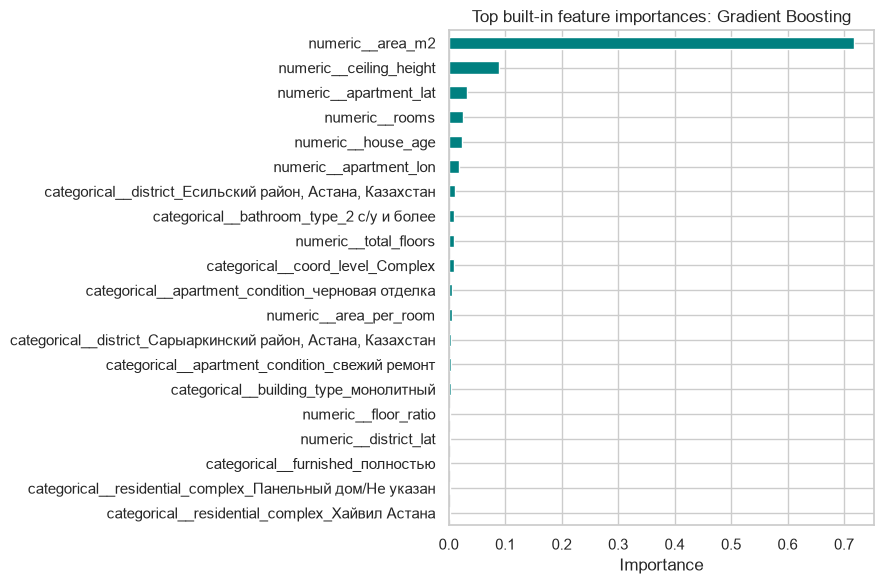

,importance
numeric__area_m2,0.717213
numeric__ceiling_height,0.088613
numeric__apartment_lat,0.032760
numeric__rooms,0.025087
numeric__house_age,0.023720
numeric__apartment_lon,0.018346
"categorical__district_Есильский район, Астана, Казахстан",0.011920
categorical__bathroom_type_2 с/у и более,0.010027
numeric__total_floors,0.009070
categorical__coord_level_Complex,0.008877


Interpretation: importances describe this fitted model's predictive use of features, not causal effects.


In [7]:
traditional_models = {**fitted_base, **{name: search.best_estimator_ for name, search in searches.items()}}
traditional_validation = pd.DataFrame([{"Model": name, **evaluate(y_val, model.predict(X_val))} for name, model in traditional_models.items()]).set_index("Model")
display(traditional_validation.sort_values("RMSE (log)").round(3))

best_traditional_name = traditional_validation["RMSE (log)"].idxmin()
best_traditional = traditional_models[best_traditional_name]
print("Traditional model selected using validation RMSE:", best_traditional_name)

feature_names = best_traditional.named_steps["preprocessor"].get_feature_names_out()
tree_model = best_traditional.named_steps["model"]
if hasattr(tree_model, "feature_importances_"):
    importance = pd.Series(tree_model.feature_importances_, index=feature_names).sort_values(ascending=False).head(20)
    plt.figure(figsize=(9, 6)); importance.sort_values().plot.barh(color="teal")
    plt.title(f"Top built-in feature importances: {best_traditional_name}"); plt.xlabel("Importance")
    plt.tight_layout(); plt.savefig(FIG_DIR / "evaluation" / "feature_importance.png", dpi=160); plt.show()
    display(importance.to_frame("importance"))
    print("Interpretation: importances describe this fitted model's predictive use of features, not causal effects.")


## 7. Unsupervised learning: K-Means clustering

K-Means is exploratory and is not inserted into the regression pipeline. It uses meaningful numerical apartment characteristics, including price, which is appropriate here because the goal is market segmentation rather than prediction. Features are median-imputed and standardized because K-Means is distance-based. The elbow curve (inertia) and silhouette score jointly guide the choice of cluster count.


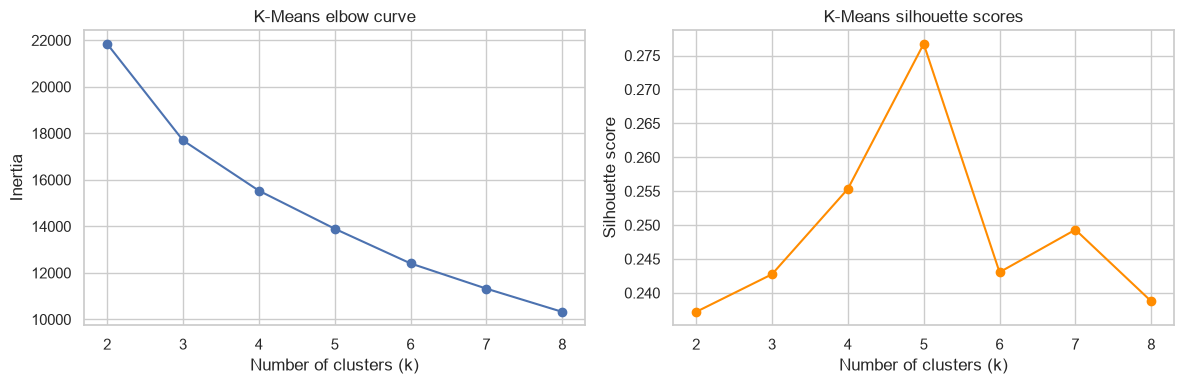

Selected k=5: highest tested silhouette score (0.277); inspect elbow curve for practical confirmation.


,Listings,Mean price (KZT),Median price (KZT),Mean area (m²),Mean rooms,Mean house age
cluster,,,,,,
0,156,23907044.86,23500000.0,55.15,2.42,44.44
1,374,34208532.63,31895000.0,56.53,1.99,3.82
2,807,86982413.95,78000000.0,117.97,3.48,6.56
3,1808,38509241.55,36500000.0,55.95,1.96,3.56
4,941,31843548.64,30000000.0,61.13,2.00,9.69


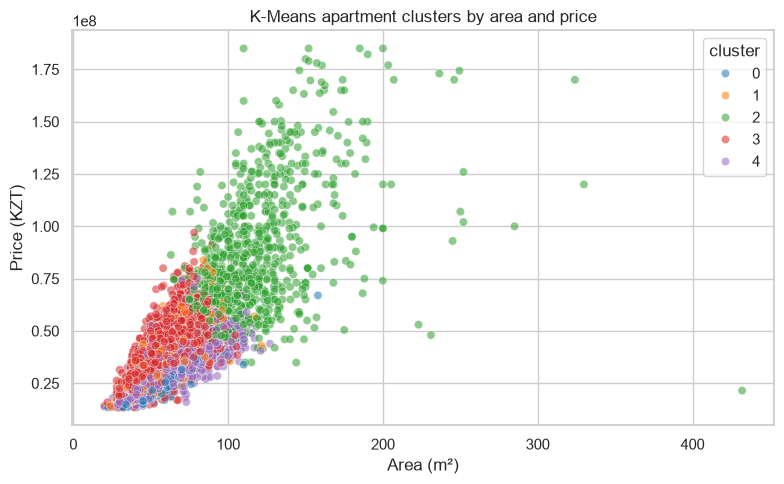

In [8]:
cluster_candidates = [c for c in [AREA_COL, ROOMS_COL, "house_age", "floor_ratio", LAT_COL, LON_COL] if c and c in df.columns]
cluster_frame = df[[TARGET] + list(dict.fromkeys(cluster_candidates))].copy()
cluster_frame = cluster_frame.select_dtypes(include="number").dropna(axis=1, how="all")
cluster_data = SimpleImputer(strategy="median").fit_transform(cluster_frame)
cluster_scaled = StandardScaler().fit_transform(cluster_data)
ks = range(2, min(9, len(cluster_frame) - 1))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=RANDOM_STATE)
    labels = km.fit_predict(cluster_scaled)
    inertias.append(km.inertia_); silhouettes.append(silhouette_score(cluster_scaled, labels))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, marker="o"); ax[0].set(title="K-Means elbow curve", xlabel="Number of clusters (k)", ylabel="Inertia")
ax[1].plot(list(ks), silhouettes, marker="o", color="darkorange"); ax[1].set(title="K-Means silhouette scores", xlabel="Number of clusters (k)", ylabel="Silhouette score")
plt.tight_layout(); plt.savefig(FIG_DIR / "clustering" / "cluster_selection.png", dpi=160); plt.show()
selected_k = list(ks)[int(np.argmax(silhouettes))]
print(f"Selected k={selected_k}: highest tested silhouette score ({max(silhouettes):.3f}); inspect elbow curve for practical confirmation.")
kmeans = KMeans(n_clusters=selected_k, init="k-means++", n_init=20, random_state=RANDOM_STATE)
df["cluster"] = kmeans.fit_predict(cluster_scaled)
cluster_summary = df.groupby("cluster").agg(**{"Listings": (TARGET, "size"), "Mean price (KZT)": (TARGET, "mean"), "Median price (KZT)": (TARGET, "median")},
    **({"Mean area (m²)": (AREA_COL, "mean")} if AREA_COL else {}),
    **({"Mean rooms": (ROOMS_COL, "mean")} if ROOMS_COL else {}), **({"Mean house age": ("house_age", "mean")} if "house_age" in df else {}))
display(cluster_summary.round(2))
if AREA_COL:
    plt.figure(figsize=(8, 5)); sns.scatterplot(data=df, x=AREA_COL, y=TARGET, hue="cluster", palette="tab10", alpha=.55)
    plt.title("K-Means apartment clusters by area and price"); plt.xlabel("Area (m²)"); plt.ylabel("Price (KZT)")
    plt.tight_layout(); plt.savefig(FIG_DIR / "clustering" / "area_price_clusters.png", dpi=160); plt.show()


## 8. Dimensionality reduction: PCA

PCA is applied to standardized, median-imputed numerical training features. It finds directions of greatest variance, which can simplify exploration but makes features less directly interpretable. The scree and cumulative-variance plots report how much information components retain. The PCA plot uses K-Means labels only for visual exploration.


Numerical PCA features: 15 | components for 90%: 9; for 95%: 11
First two components explain 33.8% of numerical-feature variance.


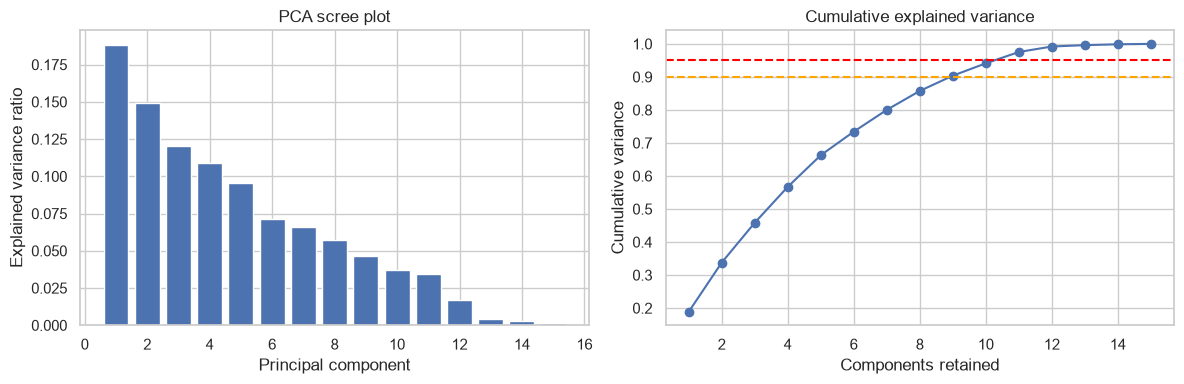

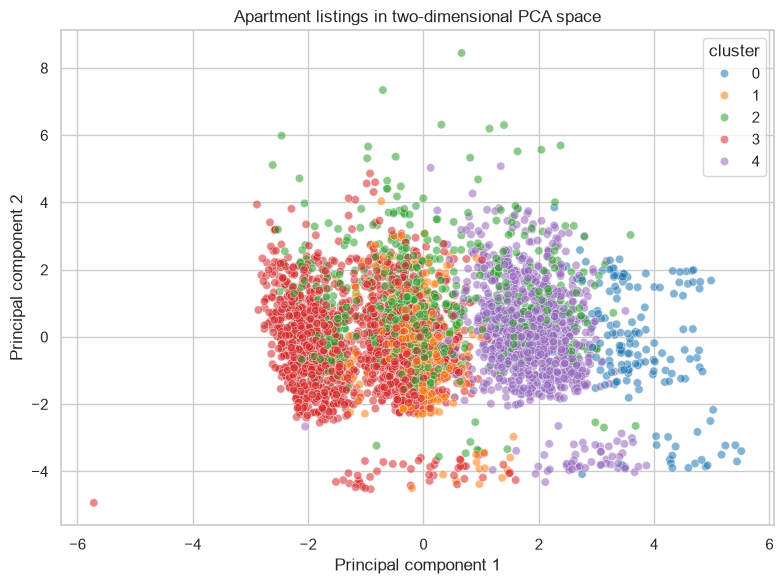

In [9]:
pca_features = [c for c in df.drop(columns=[TARGET, "cluster"], errors="ignore").select_dtypes(include="number").columns if df.loc[X_train.index, c].notna().any()]
pca_imputer = SimpleImputer(strategy="median")
pca_scaler = StandardScaler()
pca_train = pca_scaler.fit_transform(pca_imputer.fit_transform(df.loc[X_train.index, pca_features]))
pca = PCA(random_state=RANDOM_STATE).fit(pca_train)
cum_var = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.argmax(cum_var >= .90) + 1); n95 = int(np.argmax(cum_var >= .95) + 1)
print(f"Numerical PCA features: {len(pca_features)} | components for 90%: {n90}; for 95%: {n95}")
print(f"First two components explain {pca.explained_variance_ratio_[:2].sum():.1%} of numerical-feature variance.")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(pca.explained_variance_ratio_)+1), pca.explained_variance_ratio_); ax[0].set(title="PCA scree plot", xlabel="Principal component", ylabel="Explained variance ratio")
ax[1].plot(range(1, len(cum_var)+1), cum_var, marker="o"); ax[1].axhline(.90, color="orange", ls="--"); ax[1].axhline(.95, color="red", ls="--"); ax[1].set(title="Cumulative explained variance", xlabel="Components retained", ylabel="Cumulative variance")
plt.tight_layout(); plt.savefig(FIG_DIR / "pca" / "pca_variance.png", dpi=160); plt.show()
pca_all = pca.transform(pca_scaler.transform(pca_imputer.transform(df[pca_features])))[:, :2]
plt.figure(figsize=(8, 6)); sns.scatterplot(x=pca_all[:, 0], y=pca_all[:, 1], hue=df["cluster"], palette="tab10", alpha=.55)
plt.title("Apartment listings in two-dimensional PCA space"); plt.xlabel("Principal component 1"); plt.ylabel("Principal component 2")
plt.tight_layout(); plt.savefig(FIG_DIR / "pca" / "pca_clusters.png", dpi=160); plt.show()


## 9. Artificial neural network (appropriate deep learning for tabular data)

The dataset is tabular, so a feedforward ANN is the relevant deep-learning component; CNNs, NLP models, and unrelated datasets would not be methodologically appropriate. The ANN reuses the training-only fitted preprocessing. It has Dense layers of 128, 64, and 32 ReLU units, 0.2 dropout after the first two layers, a linear output, Adam optimization, MSE loss, and EarlyStopping. Validation data guides early stopping; test data is never used during ANN training.


TensorFlow: 2.22.0-rc0


ANN stopped after 33 epochs; best validation loss: 1.21411


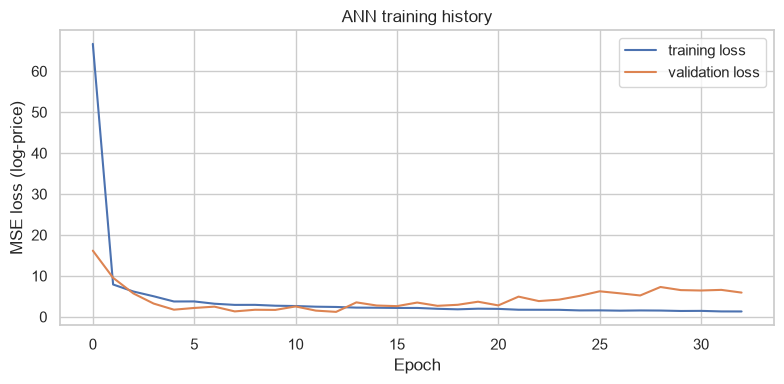

RMSE (log)    1.102000e+00
MAE (log)     1.020000e+00
R2           -3.916000e+00
MAE (KZT)     3.082908e+07
MedAPE (%)    6.443600e+01
Name: ANN validation, dtype: float64

In [10]:
if importlib.util.find_spec("tensorflow") is None:
    raise ImportError("TensorFlow is required for the ANN. Install the project requirements in a Python version supported by TensorFlow, then restart the kernel.")
import tensorflow as tf
from tensorflow import keras
print(f"TensorFlow: {tf.__version__}")

np.random.seed(RANDOM_STATE); tf.keras.utils.set_random_seed(RANDOM_STATE)
ann_preprocessor = make_preprocessor().fit(X_train, y_train)
X_train_ann = ann_preprocessor.transform(X_train).astype("float32")
X_val_ann = ann_preprocessor.transform(X_val).astype("float32")
X_test_ann = ann_preprocessor.transform(X_test).astype("float32")

ann = keras.Sequential([
    keras.layers.Input(shape=(X_train_ann.shape[1],)),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dropout(.20),
    keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(.20),
    keras.layers.Dense(32, activation="relu"), keras.layers.Dense(1, activation="linear")])
ann.compile(optimizer=keras.optimizers.Adam(learning_rate=.001), loss="mse", metrics=["mae"])
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True), keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=8, factor=.5, min_lr=1e-5)]
history = ann.fit(X_train_ann, y_train, validation_data=(X_val_ann, y_val), epochs=250, batch_size=32, verbose=0, callbacks=callbacks)
print(f"ANN stopped after {len(history.history['loss'])} epochs; best validation loss: {min(history.history['val_loss']):.5f}")
plt.figure(figsize=(8, 4)); plt.plot(history.history["loss"], label="training loss"); plt.plot(history.history["val_loss"], label="validation loss")
plt.title("ANN training history"); plt.xlabel("Epoch"); plt.ylabel("MSE loss (log-price)"); plt.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "ann" / "training_history.png", dpi=160); plt.show()
ann_val_metrics = evaluate(y_val, ann.predict(X_val_ann, verbose=0).ravel())
display(pd.Series(ann_val_metrics, name="ANN validation").round(3))


## 10. Unified model comparison and final test evaluation

All models in the validation comparison used exactly the same split and metric definitions. The model with the lowest validation log-RMSE is selected. Its selected approach is then refit on train + validation only, and the test partition is used for the first and final time. The ANN selection is based on its validation metrics and, if selected, is retrained with an internal validation holdout from train + validation—not with test data.


,RMSE (log),MAE (log),R2,MAE (KZT),MedAPE (%)
Model,,,,,
Gradient Boosting,0.162,0.121,0.893,5.795310e+06,9.418
Random Forest,0.169,0.125,0.884,5.983751e+06,9.490
Linear Regression,0.209,0.157,0.823,7.681463e+06,11.926
Decision Tree,0.216,0.165,0.810,7.891847e+06,12.569
Decision Tree (tuned),0.219,0.168,0.806,8.336173e+06,13.333
KNN,0.237,0.178,0.773,8.181777e+06,13.992
KNN (tuned),0.240,0.178,0.766,8.318538e+06,13.106
Median baseline,0.500,0.398,-0.013,1.791594e+07,33.929
Artificial Neural Network,1.102,1.020,-3.916,3.082908e+07,64.436


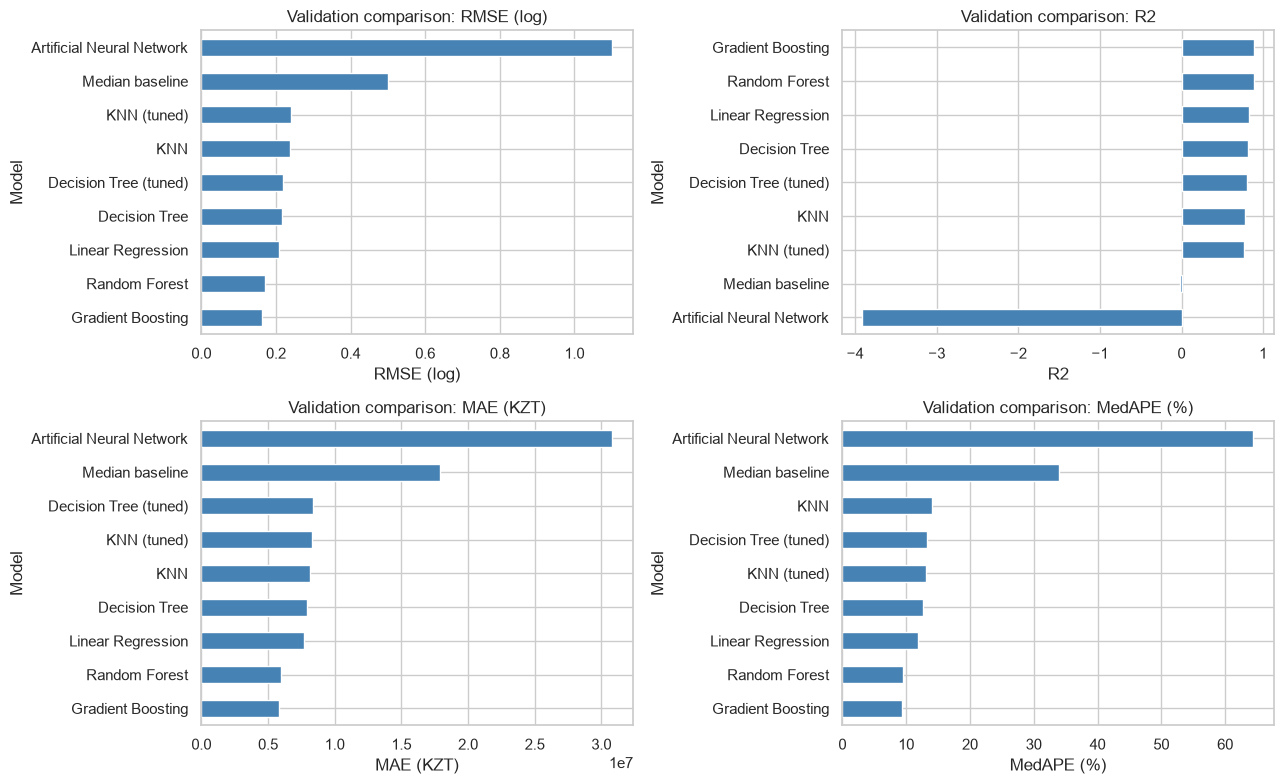

Selected model: Gradient Boosting


RMSE (log)          0.167
MAE (log)           0.125
R2                  0.892
MAE (KZT)     6097216.429
MedAPE (%)          9.181
Name: Final test: Gradient Boosting, dtype: float64

In [11]:
comparison = traditional_validation.copy()
comparison.loc["Artificial Neural Network"] = ann_val_metrics
comparison = comparison.sort_values("RMSE (log)")
display(comparison.round(3))
comparison.to_csv(ROOT / "reports" / "model_comparison_validation.csv")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, metric in zip(axes.ravel(), ["RMSE (log)", "R2", "MAE (KZT)", "MedAPE (%)"]):
    comparison[metric].sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"Validation comparison: {metric}"); ax.set_xlabel(metric)
plt.tight_layout(); plt.savefig(FIG_DIR / "evaluation" / "model_comparison.png", dpi=160); plt.show()

selected_name = comparison.index[0]
if selected_name == "Artificial Neural Network":
    X_fit = pd.concat([X_train, X_val]); y_fit = pd.concat([y_train, y_val])
    selected_preprocessor = make_preprocessor().fit(X_fit, y_fit)
    X_fit_ann = selected_preprocessor.transform(X_fit).astype("float32")
    # Internal validation split replaces the external validation set after selection.
    x_subtrain, x_internal, y_subtrain, y_internal = train_test_split(X_fit_ann, y_fit, test_size=.12, random_state=RANDOM_STATE)
    selected_model = keras.models.clone_model(ann); selected_model.compile(optimizer=keras.optimizers.Adam(.001), loss="mse", metrics=["mae"])
    selected_model.fit(x_subtrain, y_subtrain, validation_data=(x_internal, y_internal), epochs=len(history.history["loss"]), batch_size=32, verbose=0, callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)])
    test_pred = selected_model.predict(X_test_ann if False else selected_preprocessor.transform(X_test).astype("float32"), verbose=0).ravel()
else:
    selected_model = traditional_models[selected_name].fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
    test_pred = selected_model.predict(X_test)
    joblib.dump(selected_model, ROOT / "models" / "best_model.joblib")

test_metrics = evaluate(y_test, test_pred)
print("Selected model:", selected_name)
display(pd.Series(test_metrics, name=f"Final test: {selected_name}").round(3))
pd.DataFrame([{"Model": selected_name, **test_metrics}]).to_csv(ROOT / "reports" / "final_test_metrics.csv", index=False)


## 11. Final error analysis

The plots and tables below identify observed error patterns by price segment and district. Possible explanations such as renovation quality, exact view, building reputation, and missing amenity detail are hypotheses unless represented by data; they should not be presented as demonstrated causes.


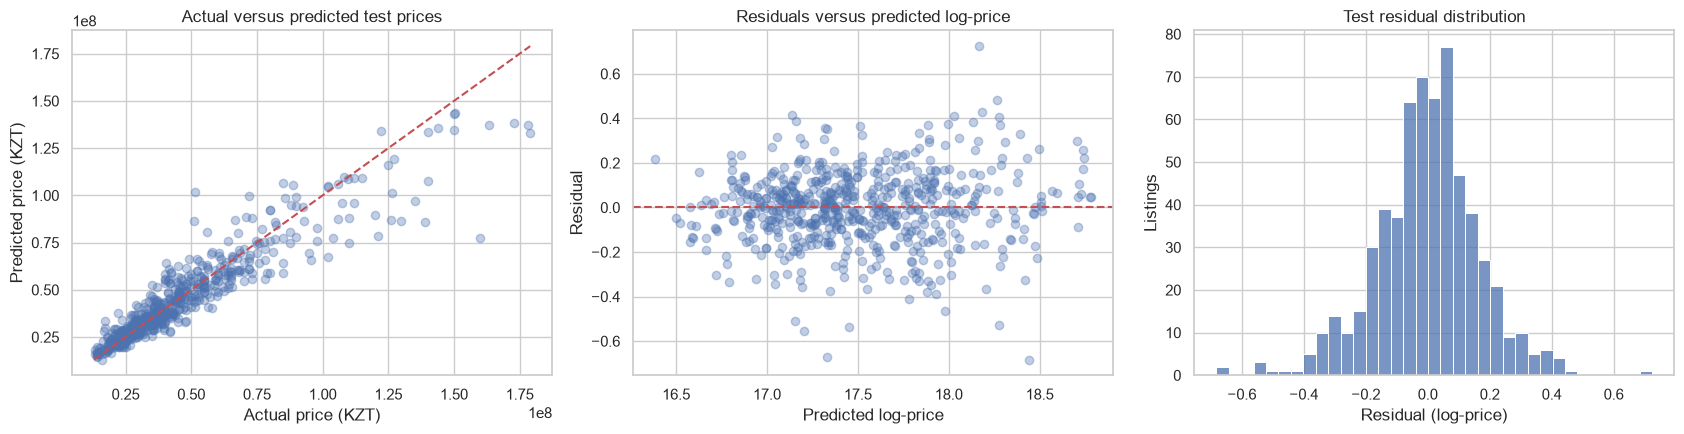

,median,mean,count
price_segment,,,
cheapest 20%,9.36,14.27,123
low,7.31,9.56,123
middle,9.36,13.75,122
high,10.77,12.68,124
top 20%,11.78,13.82,121


,median,mean,count
district,,,
"Сарыаркинский район, Астана, Казахстан",7.17,10.35,116
"Алматинский район, Астана, Казахстан",8.20,12.63,97
"Нуринский район, Астана, Казахстан",9.31,13.22,192
"Есильский район, Астана, Казахстан",9.44,12.94,158
"Байконурский район, Астана, Казахстан",12.29,13.83,24
"Астана, Казахстан",14.44,19.75,26


,actual_price,predicted_price,residual_log,ape_pct,price_segment,district
193,51500000.0,1.019507e+08,-0.68,97.96,high,"Астана, Казахстан"
90,17160000.0,3.353309e+07,-0.67,95.41,cheapest 20%,"Нуринский район, Астана, Казахстан"
368,17000000.0,2.959189e+07,-0.55,74.07,cheapest 20%,"Нуринский район, Астана, Казахстан"
769,22100000.0,3.785941e+07,-0.54,71.31,cheapest 20%,"Есильский район, Астана, Казахстан"
990,51000000.0,8.650603e+07,-0.53,69.62,high,"Астана, Казахстан"
2613,16900000.0,2.817976e+07,-0.51,66.74,cheapest 20%,"Нуринский район, Астана, Казахстан"
4284,40500000.0,6.441252e+07,-0.46,59.04,middle,"Алматинский район, Астана, Казахстан"
533,159900000.0,7.750036e+07,0.72,51.53,top 20%,"Есильский район, Астана, Казахстан"
2947,35000000.0,5.267279e+07,-0.41,50.49,middle,"Есильский район, Астана, Казахстан"
3425,41500000.0,6.126931e+07,-0.39,47.64,middle,"Алматинский район, Астана, Казахстан"


In [12]:
actual = np.expm1(y_test.to_numpy()); predicted = np.expm1(test_pred); residual = y_test.to_numpy() - test_pred
errors = pd.DataFrame({"actual_price": actual, "predicted_price": predicted, "residual_log": residual, "ape_pct": np.abs(actual-predicted)/actual*100}, index=X_test.index)
errors["price_segment"] = pd.qcut(errors["actual_price"], 5, labels=["cheapest 20%", "low", "middle", "high", "top 20%"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(actual, predicted, alpha=.35); lims=[min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]; axes[0].plot(lims, lims, "r--")
axes[0].set(title="Actual versus predicted test prices", xlabel="Actual price (KZT)", ylabel="Predicted price (KZT)")
axes[1].scatter(test_pred, residual, alpha=.35); axes[1].axhline(0, color="r", ls="--"); axes[1].set(title="Residuals versus predicted log-price", xlabel="Predicted log-price", ylabel="Residual")
sns.histplot(residual, bins=35, ax=axes[2]); axes[2].set(title="Test residual distribution", xlabel="Residual (log-price)", ylabel="Listings")
plt.tight_layout(); plt.savefig(FIG_DIR / "evaluation" / "error_analysis.png", dpi=160); plt.show()
display(errors.groupby("price_segment", observed=False)["ape_pct"].agg(["median", "mean", "count"]).round(2))
if DISTRICT_COL and DISTRICT_COL in X_test:
    errors["district"] = X_test[DISTRICT_COL]
    display(errors.groupby("district")["ape_pct"].agg(["median", "mean", "count"]).query("count >= 20").sort_values("median").round(2))
display(errors.sort_values("ape_pct", ascending=False).head(10).round(2))


## 12. Limitations and ethics

**Limitations and responsible use.** Asking prices differ from negotiated transaction prices. Listing data may include duplicates, missing or inaccurate seller-entered attributes, and a time-specific market snapshot. Prediction quality can vary by district and price segment; premium homes may be harder to estimate because important details may be absent. This model is a decision-support estimate, not an official appraisal or a substitute for professional advice. Feature importance is not causality, and users should avoid treating a prediction as a fair or guaranteed price.

**Reproducibility.** Fixed seeds are used throughout. Python and library versions print during execution. The notebook has no hidden input other than the supplied CSV and is designed to run top-to-bottom in a compatible environment.


In [13]:
best_cluster = cluster_summary["Median price (KZT)"].idxmax()
conclusion = f"""## 13. Evidence-based final conclusions

**Objective achieved.** The selected model was **{selected_name}**, chosen by validation RMSE(log) = **{comparison.loc[selected_name, 'RMSE (log)']:.4f}**. On the one-time held-out test set it achieved RMSE(log) = **{test_metrics['RMSE (log)']:.4f}**, R2 = **{test_metrics['R2']:.4f}**, MAE = **{test_metrics['MAE (KZT)']:,.0f} KZT**, and MedAPE = **{test_metrics['MedAPE (%)']:.2f}%**.

**Model comparison.** The median baseline's validation MedAPE was {comparison.loc['Median baseline', 'MedAPE (%)']:.2f}%, while the selected model's was {comparison.loc[selected_name, 'MedAPE (%)']:.2f}%. The ANN was evaluated on the same validation partition and {'improved' if comparison.loc['Artificial Neural Network', 'RMSE (log)'] < comparison.loc[selected_name, 'RMSE (log)'] else 'did not improve'} on the selected traditional model (ANN RMSE(log) = {comparison.loc['Artificial Neural Network', 'RMSE (log)']:.4f}). For this moderate-sized tabular dataset, extra neural-network complexity was not justified by validation performance.

**Market structure and PCA.** K-Means selected k = {selected_k} from the tested silhouette evidence. Cluster {best_cluster} had the highest median asking price in the cluster summary; inspect the displayed table to relate it to area, rooms and age. The first two PCA components retained {pca.explained_variance_ratio_[:2].sum():.1%} of numerical-feature variance, while {n90} and {n95} components retained approximately 90% and 95%, respectively. PCA therefore supports compact visualization, but original attributes remain more interpretable.

**Remaining limitations.** These results estimate advertised—not transaction—prices and may be less reliable for premium listings, districts or features with sparse/noisy records. Future work should use verified sales, richer quality/renovation data and time-aware validation."""
display(Markdown(conclusion))


## 13. Evidence-based final conclusions

**Objective achieved.** The selected model was **Gradient Boosting**, chosen by validation RMSE(log) = **0.1624**. On the one-time held-out test set it achieved RMSE(log) = **0.1672**, R2 = **0.8924**, MAE = **6,097,216 KZT**, and MedAPE = **9.18%**.

**Model comparison.** The median baseline's validation MedAPE was 33.93%, while the selected model's was 9.42%. The ANN was evaluated on the same validation partition and did not improve on the selected traditional model (ANN RMSE(log) = 1.1019). For this moderate-sized tabular dataset, extra neural-network complexity was not justified by validation performance.

**Market structure and PCA.** K-Means selected k = 5 from the tested silhouette evidence. Cluster 2 had the highest median asking price in the cluster summary; inspect the displayed table to relate it to area, rooms and age. The first two PCA components retained 33.8% of numerical-feature variance, while 9 and 11 components retained approximately 90% and 95%, respectively. PCA therefore supports compact visualization, but original attributes remain more interpretable.

**Remaining limitations.** These results estimate advertised—not transaction—prices and may be less reliable for premium listings, districts or features with sparse/noisy records. Future work should use verified sales, richer quality/renovation data and time-aware validation.